In [3]:
# Import the libraries we need, and hide warning messages.
# pandas = tables, numpy = maths, matplotlib and seaborn = charts.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
# Hide warning messages so the output stays clean.
warnings.filterwarnings("ignore")

In [4]:
# Load the CSV file into a table (a DataFrame).
# Then show the column names so we know what data we have.
df=pd.read_csv('insurance.csv')
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [5]:
# Show the first 5 rows so we can see what the data looks like.
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [6]:
# Show each column's type and how many values it has.
# Text columns (shown as object) must be turned into numbers later.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [7]:
# Show simple statistics (count, mean, min, max) for the number columns.
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
# Count missing (empty) values in each column.
# A model cannot learn from empty cells, so we check for them first.
df.isnull().sum() # count missing values in each column

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


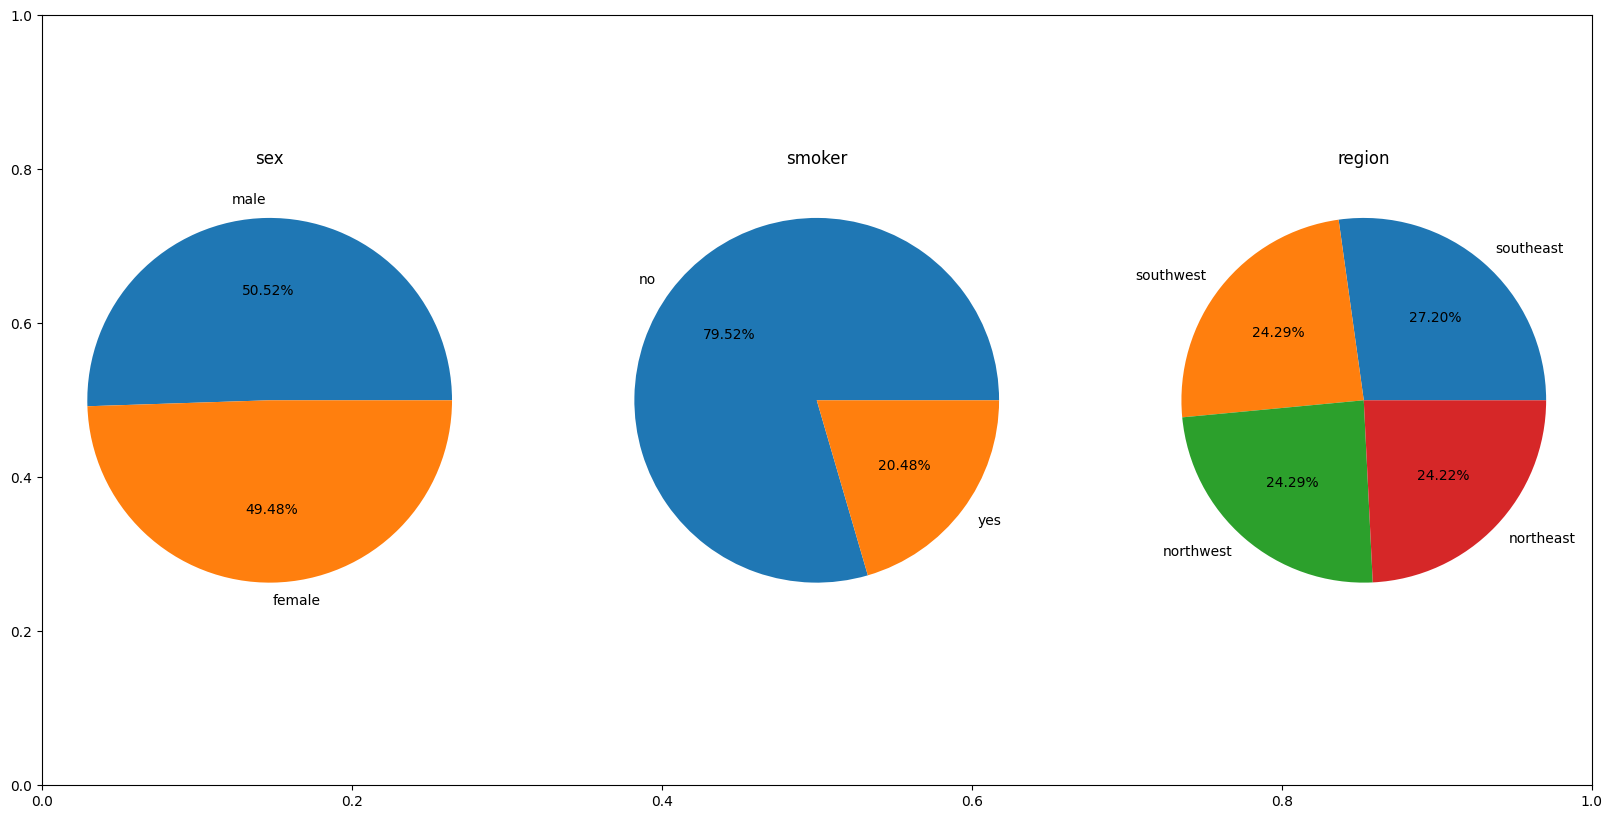

In [9]:
# Draw pie charts for sex, smoker, and region.
# This shows how the people are split, for example how many are smokers.
features=['sex', 'smoker', 'region']

plt.subplots(figsize=(20,10))
for i, col in enumerate(features):
  # One chart per column, side by side.
  plt.subplot(1,3, i+1)

  # Count how many rows have each value, such as yes and no.
  x=df[col].value_counts()
  # autopct writes the percentage on each slice.
  plt.pie(x.values, labels=x.index, autopct = '%1.2f%%')
  plt.title(col)
plt.show()

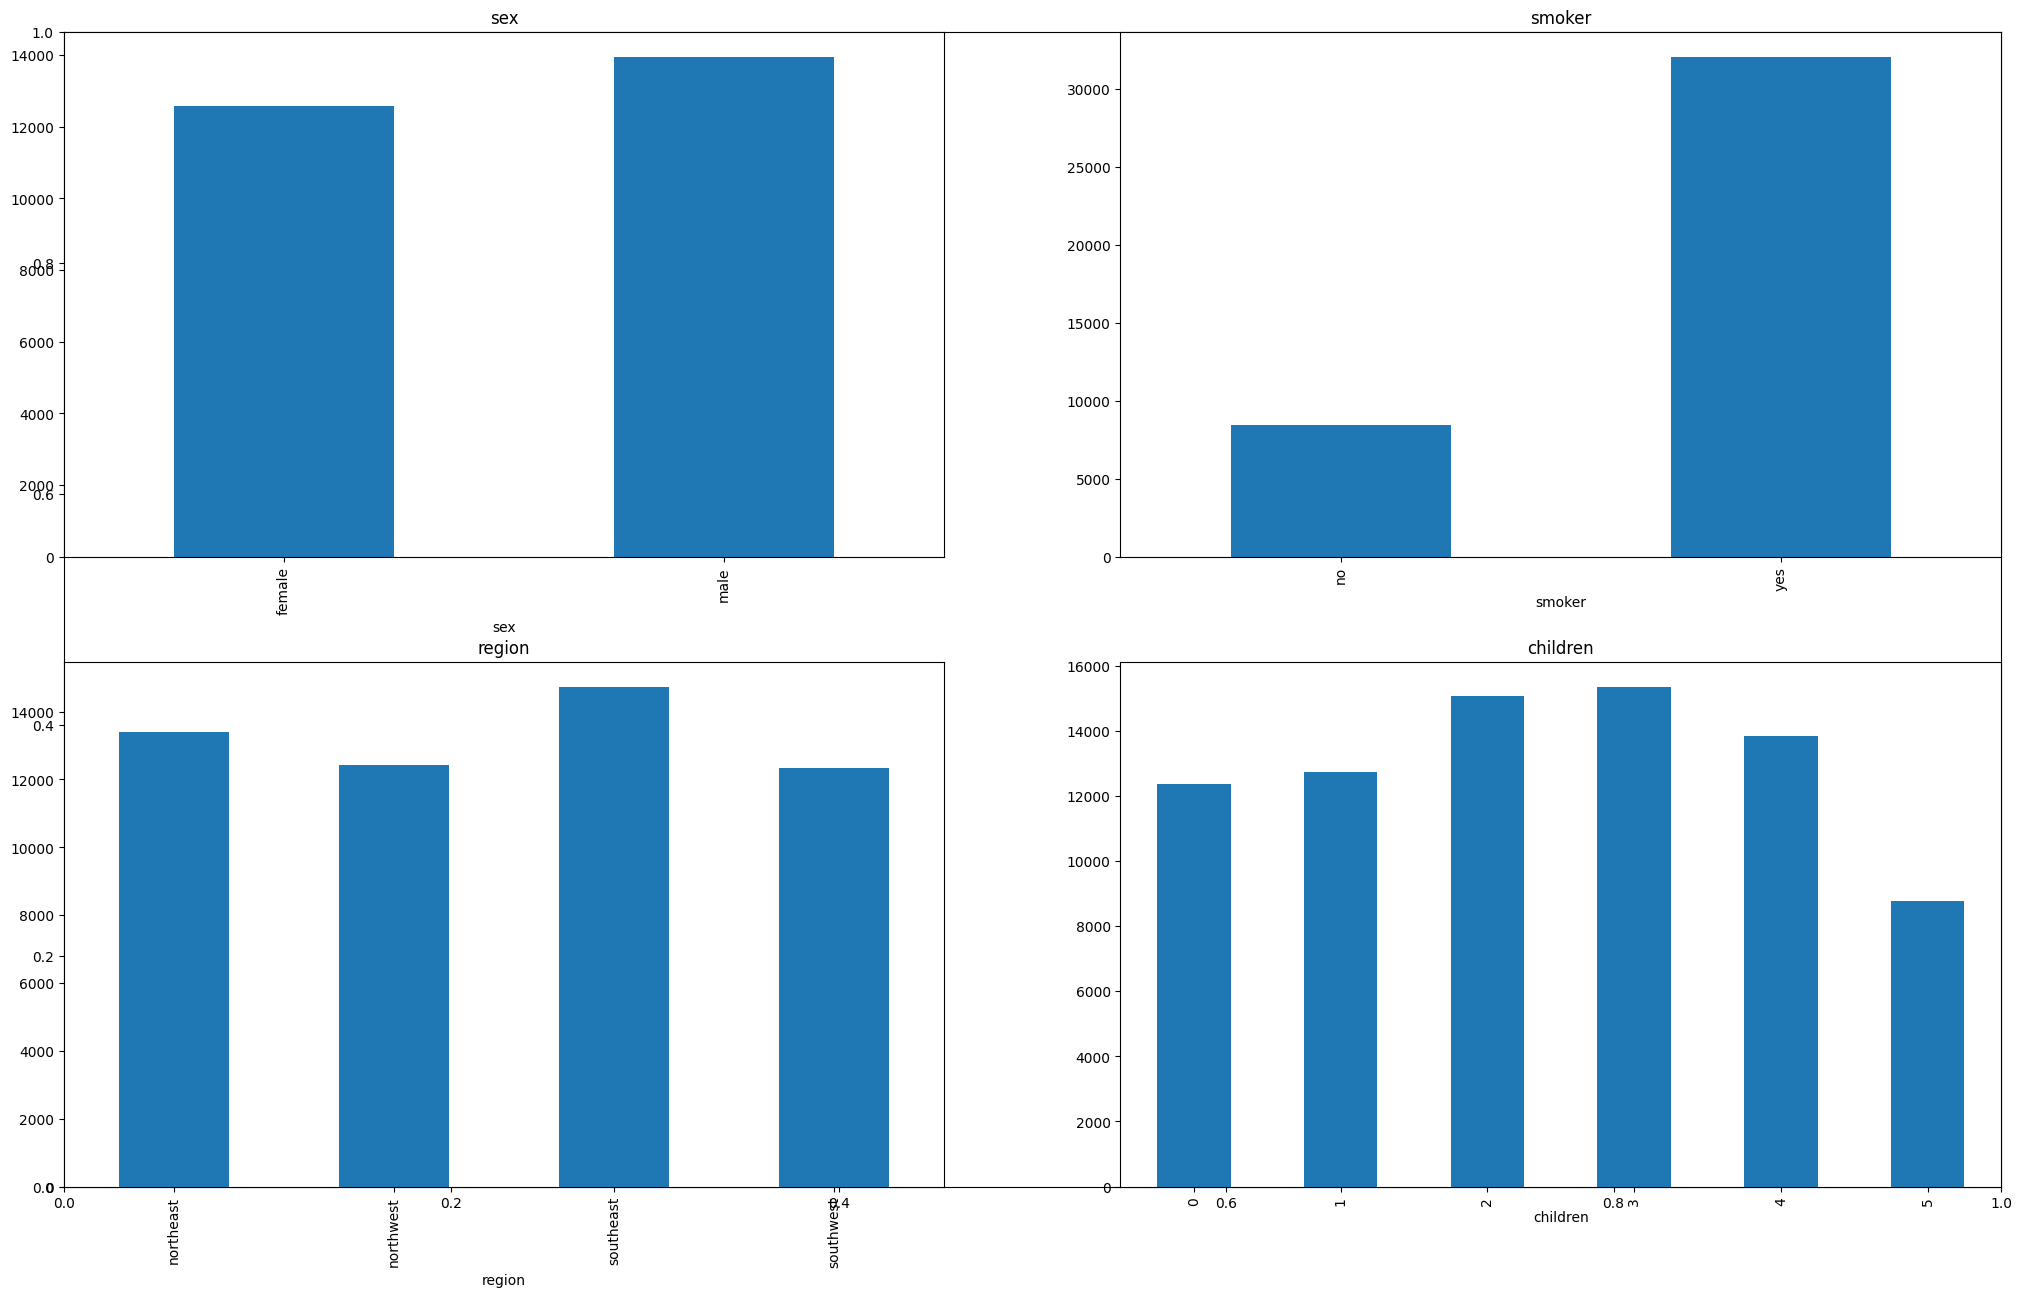

In [10]:
# Draw bar charts of the average charges for each group.
# This shows which groups pay more, for example smokers.
features.append('children')

plt.subplots(figsize=(25,15))
for i , col in enumerate(features):
  # Four charts in a 2 by 2 grid.
  plt.subplot(2,2,i+1)
  # Average charges for each group in this column.
  df.groupby(col)['charges'].mean().astype(float).plot.bar()
  plt.title(col)
plt.show()

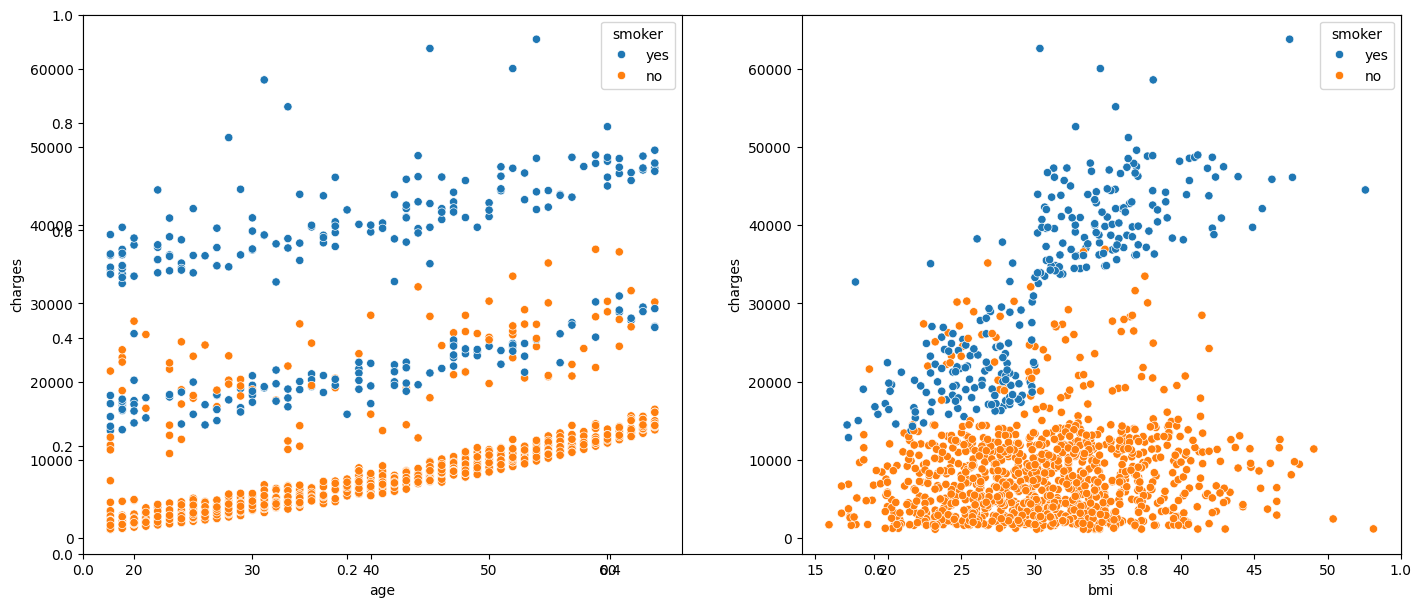

In [11]:
# Draw scatter plots of charges against age and against BMI.
# Smokers get a different colour, so we can see the effect of smoking.
feat= ['age', 'bmi']
plt.subplots(figsize=(17,7))

for i, col in enumerate(feat):
  plt.subplot(1,2,i+1)
  # hue='smoker' colours smokers and non-smokers differently.
  sns.scatterplot(data=df, x=col, y='charges', hue= 'smoker')

plt.show()

<Axes: ylabel='age'>

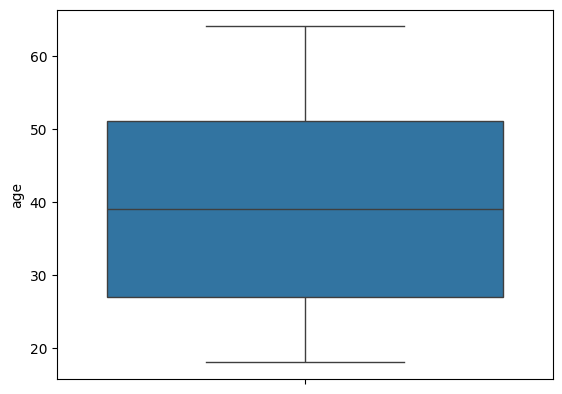

In [12]:
# Data preprocessing: clean the data before training a model.
# First remove repeated rows, then check age for outliers (extreme values).
df.drop_duplicates(inplace= True)
# A boxplot shows outliers as dots outside the whiskers. Age has none.
sns.boxplot(df['age']) # boxplot for age


<Axes: ylabel='bmi'>

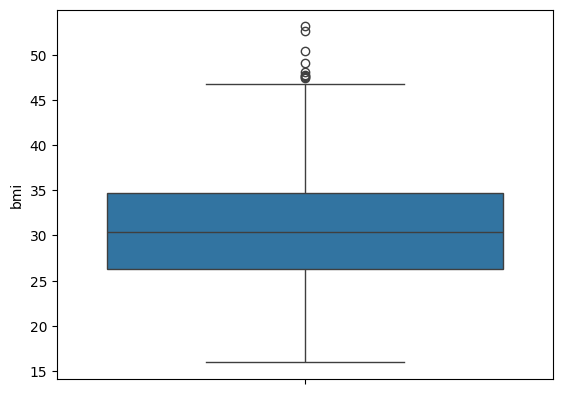

In [13]:
# Check BMI for outliers with a boxplot. BMI has some high outliers.
sns.boxplot(df['bmi'])


<Axes: ylabel='charges'>

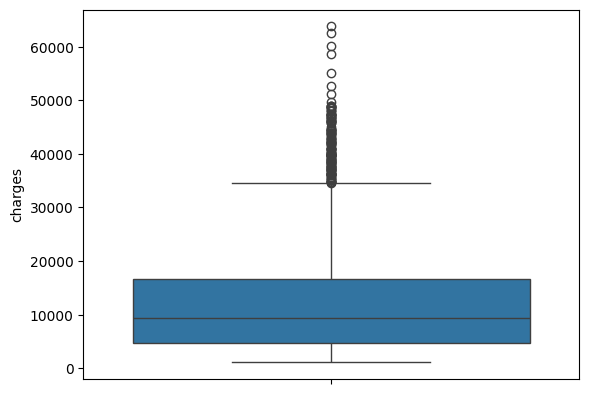

In [14]:
# Check charges for outliers with a boxplot.
# Charges has many high outliers. We keep them, because charges is what we predict.
sns.boxplot(df['charges'])


In [15]:
# Find the normal range of BMI using the IQR rule.
# IQR is the range of the middle 50% of values (Q3 minus Q1).
# A value more than 1.5 times the IQR outside that range is an outlier.
# Q1 is the 25% point, Q2 the middle, and Q3 the 75% point.
Q1=df['bmi'].quantile(0.25)
Q2=df['bmi'].quantile(0.50)
Q3=df['bmi'].quantile(0.75)
iqr= Q3-Q1
lowerlimit= Q1 - 1.5*iqr
upperlimit= Q3 + 1.5*iqr
print(f"Lower Limit of IQR : {lowerlimit} , \n Upper Limit of IQR:  {upperlimit}")


Lower Limit of IQR : 13.674999999999994 , 
 Upper Limit of IQR:  47.31500000000001


In [16]:
# Show the rows whose BMI is outside the limits we just calculated.
# The | sign means or: too low or too high.
df[(df['bmi']<lowerlimit) | (df['bmi']>upperlimit)]

,age,sex,bmi,children,smoker,region,charges
116,58,male,49.06,0,no,southeast,11381.32540
286,46,female,48.07,2,no,northeast,9432.92530
401,47,male,47.52,1,no,southeast,8083.91980
543,54,female,47.41,0,yes,southeast,63770.42801
847,23,male,50.38,1,no,southeast,2438.05520
860,37,female,47.60,2,yes,southwest,46113.51100
1047,22,male,52.58,1,yes,southeast,44501.39820
1088,52,male,47.74,1,no,southeast,9748.91060
1317,18,male,53.13,0,no,southeast,1163.46270


In [17]:
# Install feature_engine. The next cell uses it to cap the BMI outliers.
!pip install feature_engine


<Axes: ylabel='bmi'>

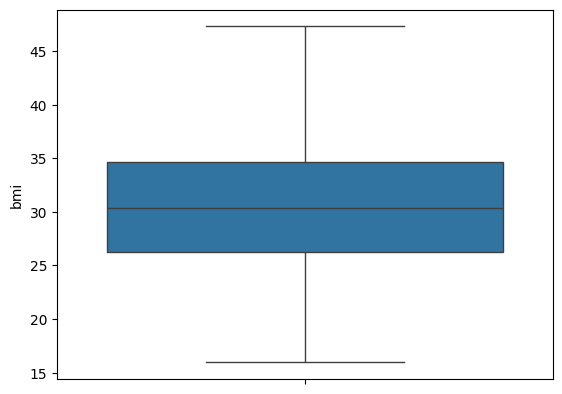

In [18]:
# Cap the BMI outliers: values past the limits are pulled back to the limit.
# No rows are deleted.
from feature_engine.outliers import ArbitraryOutlierCapper
arb= ArbitraryOutlierCapper(min_capping_dict={'bmi':lowerlimit}, max_capping_dict={'bmi':upperlimit})
df[['bmi']]= arb.fit_transform(df[['bmi']])

# Draw the boxplot again. The outlier dots should be gone.
sns.boxplot(df['bmi'])

In [19]:
# Check skew: how lopsided a column is. 0 means balanced on both sides.
print(df['bmi'].skew())
print(df['age'].skew())
# Skew is close to 0, so both are fairly symmetric. BMI is roughly bell-shaped; age is spread evenly from 18 to 64.


0.23289153320569836
0.054780773126998195


In [20]:
# Encoding: models need numbers, so each text value is replaced with a number.
# Note: smoker is coded as yes = 0 and no = 1, which is easy to mix up later.
df['sex']= df['sex'].map({'male': 0, 'female': 1})
df['smoker']= df['smoker'].map({'yes': 0, 'no': 1})
df['region']= df['region'].map({ 'northwest':0, 'northeast':1, 'southeast':2, 'southwest':3})
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,0,3,16884.92400
1,18,0,33.770,1,1,2,1725.55230
2,28,0,33.000,3,1,2,4449.46200
3,33,0,22.705,0,1,0,21984.47061
4,32,0,28.880,0,1,0,3866.85520


In [21]:
# Correlation shows how strongly two columns move together.
# Near 1 or -1 means a strong link. Near 0 means a weak link.
# In the charges row, smoker has the strongest link.
df.corr()

,age,sex,bmi,children,smoker,region,charges
age,1.000000,0.019814,0.111998,0.041536,0.025587,0.001771,0.298308
sex,0.019814,1.000000,-0.044831,-0.017848,0.076596,-0.008998,-0.058044
bmi,0.111998,-0.044831,1.000000,0.013692,-0.003151,0.156937,0.199063
children,0.041536,-0.017848,0.013692,1.000000,-0.007331,-0.002842,0.067389
smoker,0.025587,0.076596,-0.003151,-0.007331,1.000000,-0.012736,-0.787234
region,0.001771,-0.008998,0.156937,-0.002842,-0.012736,1.000000,0.010767
charges,0.298308,-0.058044,0.199063,0.067389,-0.787234,0.010767,1.000000


In [22]:
# Model development: separate the inputs from the value we want to predict.
# X holds the inputs (features). Y holds charges, the target.

X= df.drop(['charges'], axis=1)
Y= df[['charges']]

# Import the models and the scoring tools.
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
# cross_val_score tests the model on 5 different splits and averages the scores.
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [23]:
# Try Linear Regression on 10 different random splits (random_state 40 to 49).
# This checks whether the score jumps around when the split changes.
# The table says accuracy, but for regression this number is the R2 score
# (1.0 = perfect, 0 = no better than guessing the average).
l1=[]
l2=[]
l3=[]
cvs=0

for i in range(40,50):
  xtrain, xtest, ytrain, ytest= train_test_split(X,Y, test_size=0.2, random_state=i)
  lrmodel=LinearRegression()
  lrmodel.fit(xtrain, ytrain)
  # .score() on a regression model returns the R2 score.
  l1.append(lrmodel.score(xtrain, ytrain))
  l2.append(lrmodel.score(xtest, ytest))
  # This cross-validation uses all of X and Y, so the score is the same every loop.
  cvs=(cross_val_score(lrmodel, X,Y, cv=5,)).mean()
  l3.append(cvs)
  df1= pd.DataFrame({'training accuracy': l1, 'testing accuracy': l2, 'cvs ': l3})
df1


,training accuracy,testing accuracy,cvs
0,0.741659,0.778409,0.74707
1,0.756401,0.706267,0.74707
2,0.729542,0.806239,0.74707
3,0.754260,0.732791,0.74707
4,0.742966,0.779591,0.74707
5,0.753281,0.731769,0.74707
6,0.741261,0.776456,0.74707
7,0.731940,0.796173,0.74707
8,0.751915,0.741742,0.74707
9,0.756348,0.722565,0.74707


In [24]:
# Keep 80% of the rows for training and 20% for testing.
# Then train Linear Regression, a simple baseline to compare the other models with.
xtrain, xtest, ytrain, ytest= train_test_split(X,Y, test_size=0.2,random_state=42)

lrmodel=LinearRegression()
lrmodel.fit(xtrain, ytrain)
# Three R2 scores: training, testing, and the 5-fold cross-validation average.
print(lrmodel.score(xtrain, ytrain))
print(lrmodel.score(xtest, ytest))
print(cross_val_score(lrmodel, X,Y, cv=5,).mean())

0.7295415541376447
0.8062391115570589
0.7470697972809901


In [25]:
# Try SVR (support vector regression).
# It scores badly here because SVR needs scaled features (columns on a similar range), and we did not scale them.
from sklearn.metrics import r2_score
svrmodel=SVR()
svrmodel.fit(xtrain, ytrain)
# Predict charges for the training rows and the testing rows.
ypredtrain1= svrmodel.predict(xtrain)
ypredtest1=svrmodel.predict(xtest)
print(r2_score(ytrain, ypredtrain1))
print(r2_score(ytest, ypredtest1))
print(cross_val_score(svrmodel, X,Y, cv=5,).mean())

-0.10151350043755136
-0.13444534881340808
-0.10374264417397842


In [26]:
# Try a Random Forest: many decision trees that vote together.
# A train score near 0.97 and a test score near 0.88 means a bit of overfitting
# (the model memorises the training rows instead of learning a general rule).
rfmodel= RandomForestRegressor(random_state=40)
rfmodel.fit(xtrain, ytrain)
ypredtrain2=rfmodel.predict(xtrain)
ypredtest2= rfmodel.predict(xtest)

print('Random Forest regressor : ')
print(r2_score(ytrain, ypredtrain2))
print(r2_score(ytest, ypredtest2))
print(cross_val_score(rfmodel, X,Y, cv=5,).mean())

Random Forest regressor : 
0.974361986760317
0.8808212927133604
0.8357052274726285


In [27]:
# Tune the Random Forest with grid search: try each setting and keep the best.
# n_estimators is the number of trees.
from sklearn.model_selection import GridSearchCV
estimator= RandomForestRegressor(random_state= 42)
# Tree counts to try.
param_grid= { 'n_estimators': [10,40,50,98,100,120,150]}
# Score each setting with the R2 score, using 5-fold cross-validation.
grid= GridSearchCV(estimator, param_grid, scoring= 'r2', cv=5)
grid.fit(xtrain, ytrain)
print(grid.best_params_)
# Train with 120 trees. Note: grid search suggested 98.
rfmodel= RandomForestRegressor(random_state=42,  n_estimators=120)
rfmodel.fit(xtrain, ytrain)
ypredtrain2=rfmodel.predict(xtrain)
ypredtest2= rfmodel.predict(xtest)
print(" n_estimators = ", 120)
print(r2_score(ytrain, ypredtrain2))
print(r2_score(ytest, ypredtest2))
print(cross_val_score(rfmodel, X,Y, cv=5,).mean())

{'n_estimators': 98}
 n_estimators =  120
0.9744962513556507
0.8811481535380706
0.8368189849077357


In [30]:
# Try Gradient Boosting: trees built one after another, each fixing the last one's mistakes.
# First use the default settings, then search for better ones.
gbmodel = GradientBoostingRegressor() # start with default settings
gbmodel.fit(xtrain, ytrain) # train on the training data
ypredtrain3= gbmodel.predict(xtrain) # predict charges for the training rows
ypredtest3= gbmodel.predict(xtest) # predict charges for the testing rows
print(r2_score(ytrain, ypredtrain3)) # R2 score on the training set
print(r2_score(ytest, ypredtest3))  # R2 score on the testing set
print(cross_val_score(gbmodel,X,Y, cv=5,).mean()) # average R2 across 5 splits

# Make a fresh model for the search.
estimator= GradientBoostingRegressor()
# Set up the grid search: try tree counts and learning rates (how big each fix is).
param_grid= {'n_estimators': [10,15,19,20,21,50], 'learning_rate': [0.1, 0.19, 0.2, 0.21, 0.8, 1]}
grid= GridSearchCV(estimator, param_grid, scoring= "r2", cv=5)
grid.fit(xtrain, ytrain) # run the search and keep the best settings
print(grid.best_params_)

# Train a new model with the best settings found above.
gbmodel= GradientBoostingRegressor(n_estimators= 21, learning_rate= 0.2)
gbmodel.fit(xtrain, ytrain)
ypredtrain3=gbmodel.predict(xtrain) # predict on the training set with the tuned model
ypredtest3= gbmodel.predict(xtest)  # predict on the testing set with the tuned model

print(r2_score(ytrain, ypredtrain3))
print(r2_score(ytest, ypredtest3))
print(cross_val_score(gbmodel, X,Y, cv=5,).mean()) # cross-validation score for the tuned model

0.8931345821166041
0.9042549942529599
0.8549603624817307
{'learning_rate': 0.2, 'n_estimators': 21}
0.8707118602304247
0.9018114238319178
0.8609601208840021


In [34]:
# Try XGBoost, a fast version of gradient boosting.
# First use the default settings, then search for better ones.
xgmodel= XGBRegressor() # start with default settings
xgmodel.fit(xtrain, ytrain) # train on the training data
ypredtrain4= xgmodel.predict(xtrain) # predict for the training rows
ypredtest4= xgmodel.predict(xtest) # predict for the testing rows
print(r2_score(ytrain, ypredtrain4)) # R2 score on the training data
print(r2_score(ytest, ypredtest4)) # R2 score on the testing data
print(cross_val_score(xgmodel, X,Y, cv=5,).mean()) # average R2 across 5 splits

from sklearn.model_selection import GridSearchCV # tool that tries many settings
estimator= XGBRegressor() # a fresh XGBoost model for the search
# Settings to try: number of trees, max tree depth, and gamma (how cautious a tree is about splitting).
param_grid= { 'n_estimators': [10,15,20,40,50], 'max_depth': [3,4,5], 'gamma': [0, 0.15, 0.3, 0.5,1]}
grid = GridSearchCV(estimator, param_grid, scoring= "r2", cv=5) # score each combination with 5-fold cross-validation
grid.fit(xtrain, ytrain) # run the search on the training data
print(grid.best_params_) # print the best combination found

# Train a new XGBoost model. Note: grid search suggested max_depth=3, but this model uses 4.
xgmodel= XGBRegressor(n_estimators= 15, max_depth=4, gamma=0)
xgmodel.fit(xtrain,ytrain) # train this model
ypredtrain4= xgmodel.predict(xtrain) # predict training values with this model
ypredtest4= xgmodel.predict(xtest) # predict testing values with this model
print(r2_score(ytrain, ypredtrain4)) # training R2 score
print(r2_score(ytest, ypredtest4)) # testing R2 score
print(cross_val_score(xgmodel, X,Y, cv=5,).mean()) # average R2 across 5 splits

0.995843231678009
0.8609016537666321
0.8150930523872375
{'gamma': 0, 'max_depth': 3, 'n_estimators': 15}
0.881096363067627
0.9002556204795837
0.8584396123886109


In [ ]:
# Compare all five models on the same train/test split.
# R2 score: 1.0 is perfect, 0 is no better than guessing the average.
# MAE and RMSE are the typical error in dollars. Lower is better.
models = {
    "Linear Regression": lrmodel,
    "SVR": svrmodel,
    "Random Forest": rfmodel,
    "Gradient Boosting": gbmodel,
    "XGBoost": xgmodel,
}

rows = []
for name, model in models.items():
    pred = model.predict(xtest)
    rows.append({
        "Model": name,
        "Train R2": r2_score(ytrain, model.predict(xtrain)),
        "Test R2": r2_score(ytest, pred),
        "CV R2": cross_val_score(model, X, Y, cv=5).mean(),
        "MAE": mean_absolute_error(ytest, pred),
        "RMSE": np.sqrt(mean_squared_error(ytest, pred)),
    })

results = pd.DataFrame(rows).sort_values("Test R2", ascending=False).round(3)
display(results)
results.plot.bar(x="Model", y=["Train R2", "Test R2", "CV R2"], figsize=(10, 5), title="Model comparison (R2)")
plt.show()

In [35]:
# Feature importance: how much each column helps the prediction.
# These numbers come from the best model in the XGBoost grid search above (max_depth=3), not the depth-4 model.
# Smoker is the most important feature, about 84%.
feats=pd.DataFrame(data=grid.best_estimator_.feature_importances_,index=X.columns,columns=['Importance'])
feats

,Importance
age,0.035744
sex,0.002994
bmi,0.104846
children,0.010531
smoker,0.839794
region,0.006091


In [36]:
# Keep only columns with importance above 1%.
# sex and region fall below that, so the next cell drops them.
important_feats= feats[feats['Importance']> 0.01]
important_feats

,Importance
age,0.035744
bmi,0.104846
children,0.010531
smoker,0.839794


In [37]:
# Build the final model using only the important columns.
# sex and region are removed, then the tuned XGBoost model is trained again.
df.drop(df[['sex', 'region']], axis=1, inplace=True)
# Xf and X are the same here: every remaining column except charges.
Xf= df.drop(df[['charges']], axis=1)
X= df.drop(df[['charges']], axis=1)
# Note: random_state=40 here. Earlier cells used 42, so this split is different.
xtrain, xtest, ytrain, ytest= train_test_split(Xf, Y, test_size=0.2, random_state=40)
finmodel=XGBRegressor(n_estimators= 15, max_depth=4, gamma=0)
finmodel.fit(xtrain, ytrain)
ypredtrain5= finmodel.predict(xtrain)
ypredtest5= finmodel.predict(xtest)

print(r2_score(ytrain, ypredtrain5))
print(r2_score(ytest, ypredtest5))
print(cross_val_score(finmodel, X,Y, cv=5,).mean())


0.8856475949287415
0.896310031414032
0.8591699361801147


In [38]:
# Save the trained model to a file so we can use it later without training again.
from pickle import dump
# wb means write the file as bytes, not as text.
dump(finmodel, open('insurancemodelf.pkl', 'wb'))